### Presentation figures: CARBONITE calcium transients in hiPSC-CMs, maintenance vs. Feyen media
#### Lavie Ngo
#### This notebook: Final, presentation-formatted figures, built from the CM-only (cTnT+) analysis in `6-plot-calcium-CM.ipynb`. Each figure uses the same formatting for Plate 1 and Plate 2, so the two can be compared side by side on slides.

#### Experiment info:
- Differentiated vCMs (D0: 08/31/26) were replated on D18 (09/18/26) into two 96-well plates and cultured in maintenance media until D25 (09/25/26). On D25, wells were moved to their assigned media:
    - Wells B02-B09: Maintenance media (control)
    - Wells C02-C09: Feyen maturation media (treatment)
- Plate 1: 1 week in assigned media; CARBONITE (Rhod-2) on 10/02/26, then fixed.
- Plate 2: 2 weeks in assigned media; CARBONITE (Rhod-2) on 10/09/26, then fixed.
- Spontaneous beating (not paced). 1000 frames at 101.73 Hz = 9.82 s per movie.

#### Inputs (from the pipeline, see CLAUDE.md):
- `Calcium/<plate>/calcium_features.csv` (step 4) joined to `Calcium/<plate>/ctnt_classification.csv` (step 3b) on Well + ObjectNumber.
- `Calcium/<plate>/nuclear_traces.parquet` (step 3) for the traces.

#### Rules carried over from notebook 6:
- **CMs** = cTnT+ (perinuclear cTnT ring >= 2x well background). **Active** = >= 2 peaks and peak dF/F0 >= 0.2.
- **Excluded:** Plate 1 C07 (alignment failed). **Flagged:** Plate 2 C05/C06 (debris), drawn with dashed lines.
- Plate 1 B02 is kept: its aligned "transients" are mostly a slow decline already underway at frame 0, but there is no objective criterion to exclude it yet.
- The functions below are copied from notebook 6 (same names, same maths). If one changes there, change it here too.

In [1]:
# Reusable functions
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import calcium

CALCIUM_DIR = Path("../../Calcium")
FIG_DIR = CALCIUM_DIR / "figures" / "presentation"

PLATES = {
    "plate1": "Plate 1: 1 week",
    "plate2": "Plate 2: 2 weeks",
}
CONDITIONS = ["Maintenance media", "Feyen maturation media"]
CONDITION_ROWS = {"Maintenance media": "B", "Feyen maturation media": "C"}
CONDITION_LABELS = {"Maintenance media": "Maintenance", "Feyen maturation media": "Feyen"}
CONDITION_COLORS = {"Maintenance media": "#4C72B0", "Feyen maturation media": "#DD8452"}
FLAGGED_WELLS = {("plate2", "C05"): "debris", ("plate2", "C06"): "debris"}

DFF_SETTINGS = {"f0_pct": calcium.F0_PCT, "smooth": calcium.SMOOTH, "trim": calcium.TRIM}
MIN_PEAK_DFF = 0.2      # "active" = beating and peak dF/F0 >= this

# Aligned transients (as in notebook 6)
ALIGN_PRE = 50          # frames before the transient start, ~0.49 s
ALIGN_POST = 350        # frames after, ~3.44 s
ALIGN_FRAC = 0.1        # align on the 10%-of-amplitude crossing of the rise
ALIGN_N = 50            # transients sampled per well
ALIGN_SEED = 0
ALIGN_MIN_WELL = 5      # wells with fewer transients are left out of the figure (counted in the legend)
ALIGN_MIN_REL = 0.5     # a transient counts only if its amplitude is >= this x the nucleus's largest

# Presentation style
STYLE = {
    "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12, "legend.fontsize": 10,
    "xtick.labelsize": 11, "ytick.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
}


def load_features(plates=PLATES):
    """One row per nucleus in the movie (step 4), with the step-3b cTnT call joined on Well + ObjectNumber."""
    frames = []
    for plate in plates:
        f = pd.read_csv(CALCIUM_DIR / plate / "calcium_features.csv")
        c = pd.read_csv(CALCIUM_DIR / plate / "ctnt_classification.csv",
                        usecols=["Well", "ObjectNumber", "ctnt_ratio", "cTnT_pos"])
        frames.append(f.merge(c, on=["Well", "ObjectNumber"], how="left", validate="1:1"))
    features = pd.concat(frames, ignore_index=True)
    if features.cTnT_pos.isna().any():
        raise ValueError("Some nuclei have no cTnT call; re-run 3b-classify-ctnt.py.")
    features["cTnT_pos"] = features.cTnT_pos.astype(bool)
    return features


def load_traces(plate, well):
    """Raw traces for one well -> (ObjectNumber array, F matrix [nuclei x frames], dt)."""
    tr = pd.read_parquet(CALCIUM_DIR / plate / "nuclear_traces.parquet", filters=[("Well", "==", well)])
    if tr.empty:
        raise ValueError(f"No traces for {plate} {well} (excluded or not extracted).")
    return tr.ObjectNumber.to_numpy(), np.stack(tr.CalciumTrace.to_numpy()), float(tr.FrameInterval_s.iloc[0])


def dff_matrix(F, settings=DFF_SETTINGS):
    """dF/F0 for every row of F with calcium.dff(), so plots use the pipeline's exact maths."""
    return np.stack([calcium.dff(row, settings["f0_pct"], settings["smooth"], settings["trim"]) for row in F])


def first_complete_transient(d, dt, pre=ALIGN_PRE, post=ALIGN_POST, frac=ALIGN_FRAC, min_rel=ALIGN_MIN_REL):
    """Start index of the first full-size transient whose whole window fits in the trace, or None.
    Start = first frame of the rise above (local baseline + frac x amplitude)."""
    pk = calcium.detect(d, dt, calcium.peak_height(d, calcium.SNR_K, calcium.FLOOR),
                        calcium.MIN_SEP, calcium.WIDTH)
    events = []
    for i, p in enumerate(pk):
        lo = pk[i - 1] if i > 0 else 0
        pre_seg = d[lo:p + 1]
        if len(pre_seg) < 3:
            continue
        base = pre_seg.min()
        amp = d[p] - base
        below = np.flatnonzero(pre_seg <= base + frac * amp)
        if amp > 0 and below.size:
            events.append((lo + below[-1] + 1, amp))
    if not events:
        return None
    biggest = max(amp for _, amp in events)
    for start, amp in events:
        if amp >= min_rel * biggest and start - pre >= 0 and start + post <= len(d):
            return start
    return None


def aligned_transients(plate, well, features, n_max=ALIGN_N, seed=ALIGN_SEED, min_peak_dff=MIN_PEAK_DFF):
    """Aligned dF/F0 windows for one well: active CMs only, first complete full-size transient of
    each, then a seeded random sample of up to n_max. Returns dict(t, traces, n_active, n_complete)."""
    objects, F, dt = load_traces(plate, well)
    f = features.query("Plate == @plate and Well == @well").set_index("ObjectNumber").loc[objects]
    active = (f.cTnT_pos & f.beating & (f.peak_dff >= min_peak_dff)).to_numpy()
    windows = []
    for row in dff_matrix(F[active]) if active.any() else []:
        s = first_complete_transient(row, dt)
        if s is not None:
            windows.append(row[s - ALIGN_PRE:s + ALIGN_POST])
    windows = np.array(windows).reshape(-1, ALIGN_PRE + ALIGN_POST)
    rng = np.random.default_rng(seed)
    pick = rng.choice(len(windows), size=min(n_max, len(windows)), replace=False)
    return {"t": np.arange(-ALIGN_PRE, ALIGN_POST) * dt, "traces": windows[np.sort(pick)],
            "n_active": int(active.sum()), "n_complete": len(windows)}


def collect_aligned(features, plates=PLATES):
    """aligned_transients() for every well, keyed by (plate, well)."""
    return {(plate, well): aligned_transients(plate, well, features)
            for plate in plates for well in sorted(features.query("Plate == @plate").Well.unique())}


def _save(fig, name):
    if name is None:
        return
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    for ext in ("png", "svg"):
        path = FIG_DIR / f"{name}.{ext}"
        fig.savefig(path, dpi=300, bbox_inches="tight")
        print(f"Exported: {path}")


def plot_aligned_wells(plate, aligned, ylim=None, min_well=ALIGN_MIN_WELL, export_name=None):
    """Aligned dF/F0 transients for one plate on one axis: each well's mean transient as a thin line
    (dashed = flagged well), each condition's mean of well means as a thick line. Wells with fewer
    than min_well transients are left out (the legend gives the wells and transients shown)."""
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(6, 4))
        t = next(iter(aligned.values()))["t"]
        for condition in CONDITIONS:
            color = CONDITION_COLORS[condition]
            wells = sorted(w for p, w in aligned if p == plate and w[0] == CONDITION_ROWS[condition])
            kept = [w for w in wells if len(aligned[(plate, w)]["traces"]) >= min_well]
            means = []
            for well in kept:
                m = aligned[(plate, well)]["traces"].mean(axis=0)
                means.append(m)
                ax.plot(t, m, color=color, lw=0.8, alpha=0.45,
                        ls="--" if FLAGGED_WELLS.get((plate, well)) else "-")
            n_tr = sum(len(aligned[(plate, w)]["traces"]) for w in kept)
            label = (f"{CONDITION_LABELS[condition]}: {len(kept)} well{'s' if len(kept) != 1 else ''}, "
                     f"{n_tr} transients")
            if means:
                ax.plot(t, np.mean(means, axis=0), color=color, lw=2.5, label=label)
            else:
                ax.plot([], [], color=color, lw=2.5, label=label)
        ax.axvline(0, color="0.4", ls=":", lw=1)
        ax.set_xlim(t[0], t[-1])
        if ylim is not None:
            ax.set_ylim(*ylim)
        ax.set_xlabel("Time from transient start (s)")
        ax.set_ylabel("\u0394F/F$_0$")
        ax.set_title(PLATES[plate])
        ax.legend(frameon=False, loc="upper right")
        fig.tight_layout()
        _save(fig, export_name)
        plt.show()
    return fig


def plot_well_aligned(plate, well, aligned, ylim=None, export_name=None):
    """One well's aligned dF/F0 transients: each sampled transient as a thin grey line, their mean in
    the condition colour, dotted line at the transient start (t = 0). n is given in the legend."""
    a = aligned[(plate, well)]
    condition = next(c for c, row in CONDITION_ROWS.items() if row == well[0])
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(6, 4))
        for tr in a["traces"]:
            ax.plot(a["t"], tr, color="0.6", lw=0.6, alpha=0.5)
        n = len(a["traces"])
        if n:
            ax.plot(a["t"], a["traces"].mean(axis=0), color=CONDITION_COLORS[condition], lw=2.5,
                    label=f"Mean, n = {n} transient{'s' if n != 1 else ''}")
        ax.axvline(0, color="0.4", ls=":", lw=1)
        ax.set_xlim(a["t"][0], a["t"][-1])
        if ylim is not None:
            ax.set_ylim(*ylim)
        ax.set_xlabel("Time from transient start (s)")
        ax.set_ylabel("\u0394F/F$_0$")
        ax.set_title(f"{PLATES[plate].split(':')[0]}: {well}")
        ax.legend(frameon=False, loc="upper right")
        fig.tight_layout()
        _save(fig, export_name)
        plt.show()
    return fig


def wells_ylim(aligned, keys, pad=0.05):
    """One y-range covering every individual transient in the given wells."""
    values = np.concatenate([aligned[k]["traces"].ravel() for k in keys if len(aligned[k]["traces"])])
    return (min(0, values.min()) - pad, values.max() + pad)


def shared_ylim(aligned, plates=PLATES, min_well=ALIGN_MIN_WELL, pad=0.05):
    """One y-range covering every plotted well mean, so the plates share an axis."""
    values = [a["traces"].mean(axis=0) for (p, w), a in aligned.items()
              if p in plates and len(a["traces"]) >= min_well]
    lo, hi = min(v.min() for v in values), max(v.max() for v in values)
    return (min(0, lo) - pad, hi + pad)

In [2]:
# Improve inline figure quality
%config InlineBackend.figure_format = "retina"
plt.rcParams["figure.dpi"] = 100

In [3]:
# Load per-nucleus features and the aligned windows for every well (seeded, as in notebook 6)
features = load_features()
aligned = collect_aligned(features)
YLIM = shared_ylim(aligned)    # same y-axis on both plates
print(f"{len(aligned)} wells; shared y-range {YLIM[0]:.2f} to {YLIM[1]:.2f}")

31 wells; shared y-range -0.19 to 0.61


#### Aligned calcium transients, CMs only
Each active CM's first full-size transient, shifted so its rise starts at t = 0 (10% of its amplitude), then averaged. Thin lines = one well's mean of up to 50 transients; thick line = mean of those well means (each well counts once). dF/F0 is the rise above each nucleus's resting signal. Wells with fewer than 5 transients are not drawn: on Plate 1 that leaves out 6 of 7 Feyen wells (C02, C04, C05, C06, C08, C09), which had 0-2 active CMs each.

Exported: ../../Calcium/figures/presentation/plate1_aligned-transients.png


Exported: ../../Calcium/figures/presentation/plate1_aligned-transients.svg


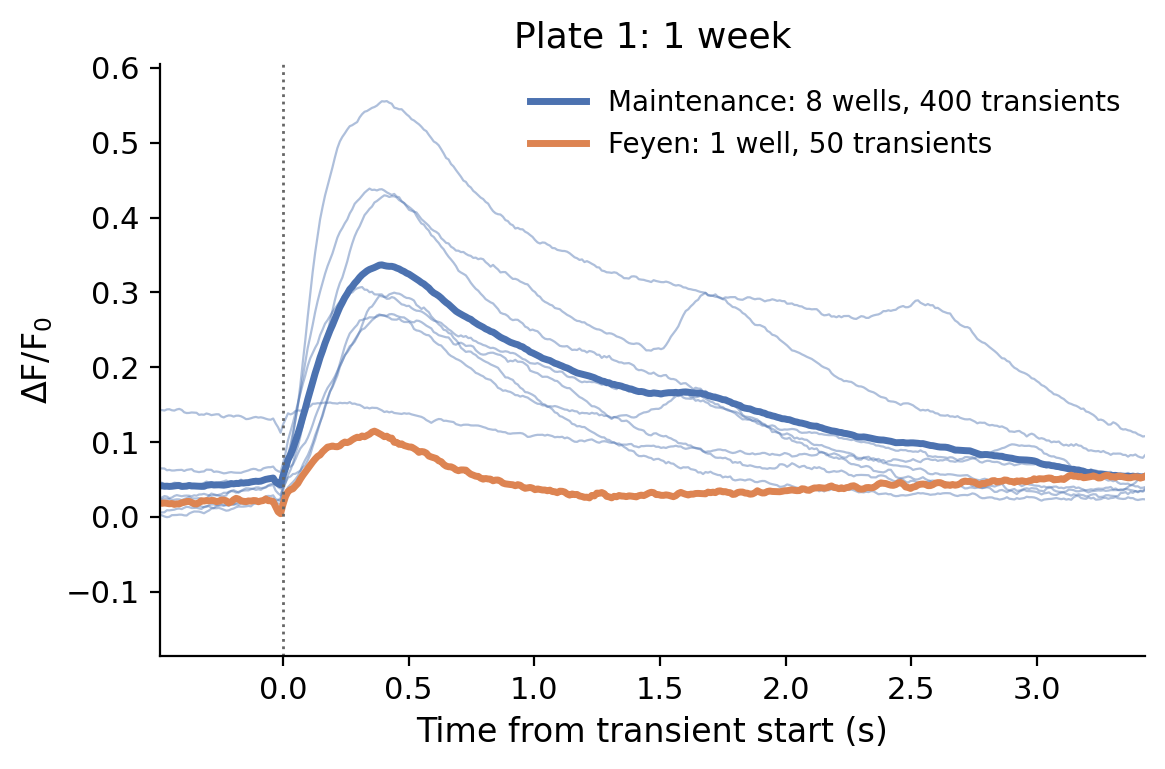

In [4]:
# Plate 1: 1 week in assigned media
plate1_aligned = plot_aligned_wells("plate1", aligned, ylim=YLIM, export_name="plate1_aligned-transients")

Exported: ../../Calcium/figures/presentation/plate2_aligned-transients.png


Exported: ../../Calcium/figures/presentation/plate2_aligned-transients.svg


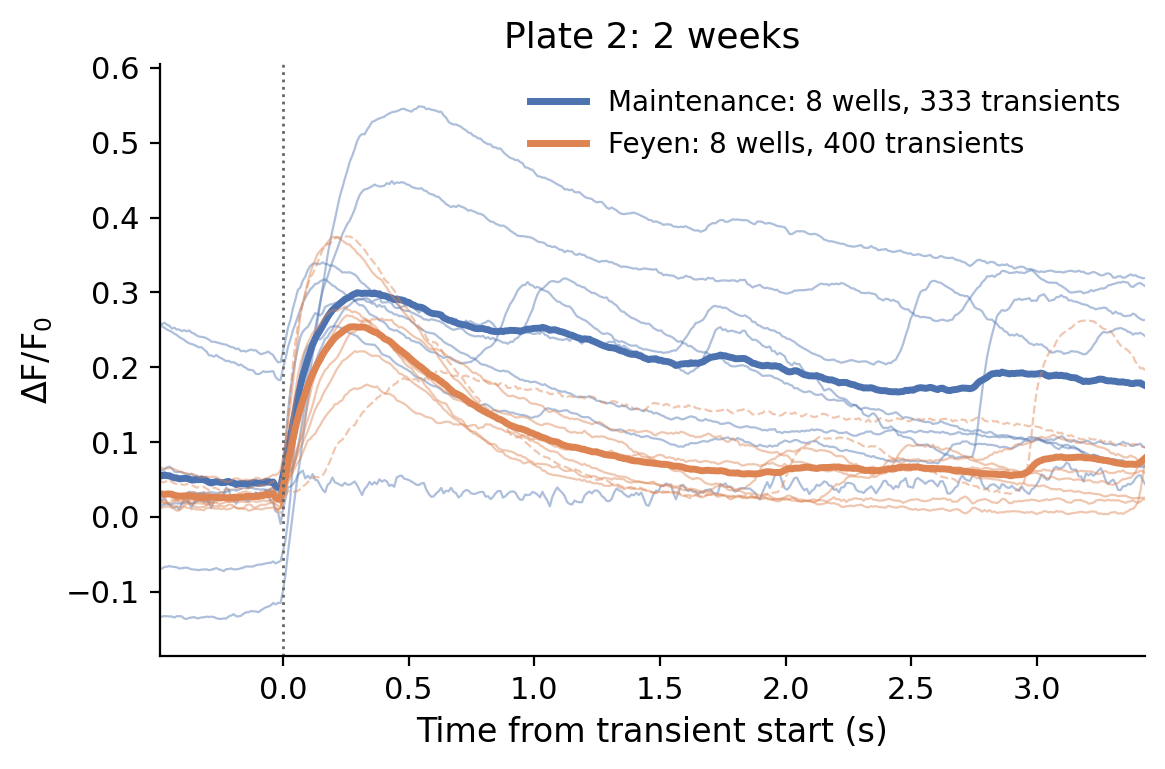

In [5]:
# Plate 2: 2 weeks in assigned media, same formatting and y-axis
plate2_aligned = plot_aligned_wells("plate2", aligned, ylim=YLIM, export_name="plate2_aligned-transients")

#### Aligned transients for the video wells (Plate 1: B04, C09; Plate 2: B06, C04)
The same aligned windows as above, for the wells shown in the videos. Grey = each sampled transient (up to 50, seeded), coloured line = their mean. All four figures share one y-axis so their sizes can be compared across wells and plates. Plate 1 C09 had a single active CM, so its panel is one trace, not an average.

shared y-range -0.09 to 1.02


Exported: ../../Calcium/figures/presentation/plate1_B04_aligned-transients.png


Exported: ../../Calcium/figures/presentation/plate1_B04_aligned-transients.svg


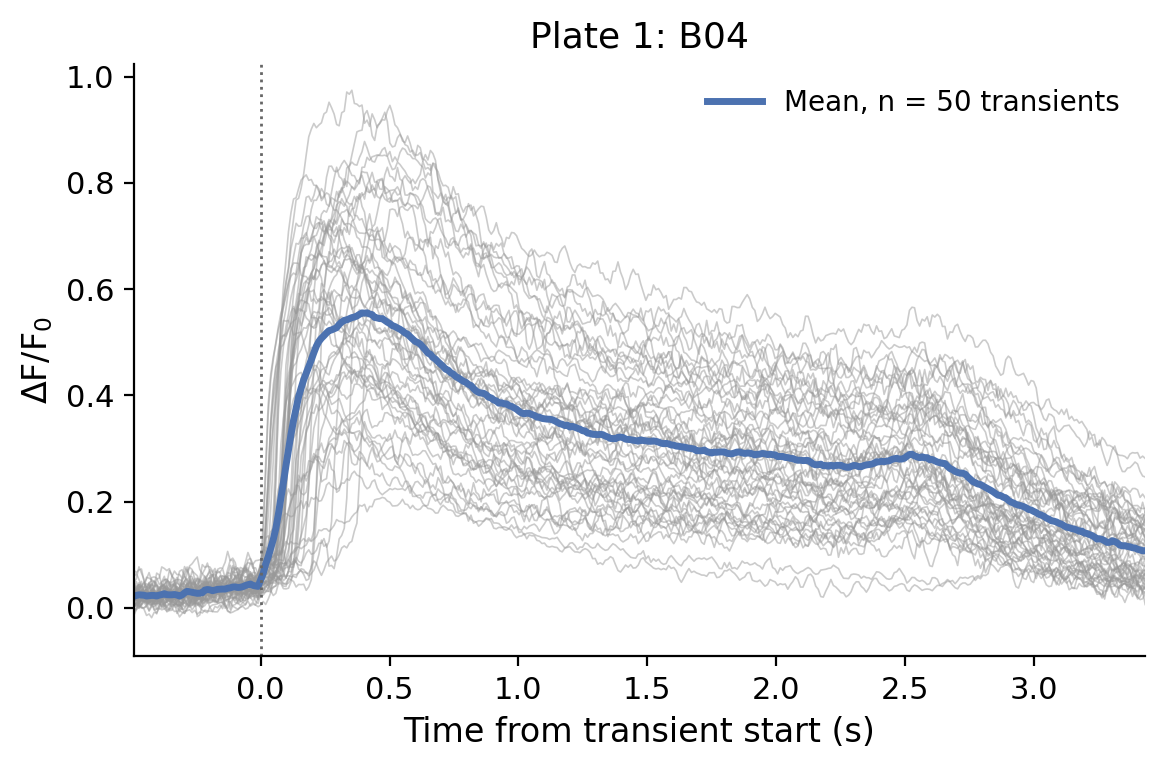

Exported: ../../Calcium/figures/presentation/plate1_C09_aligned-transients.png


Exported: ../../Calcium/figures/presentation/plate1_C09_aligned-transients.svg


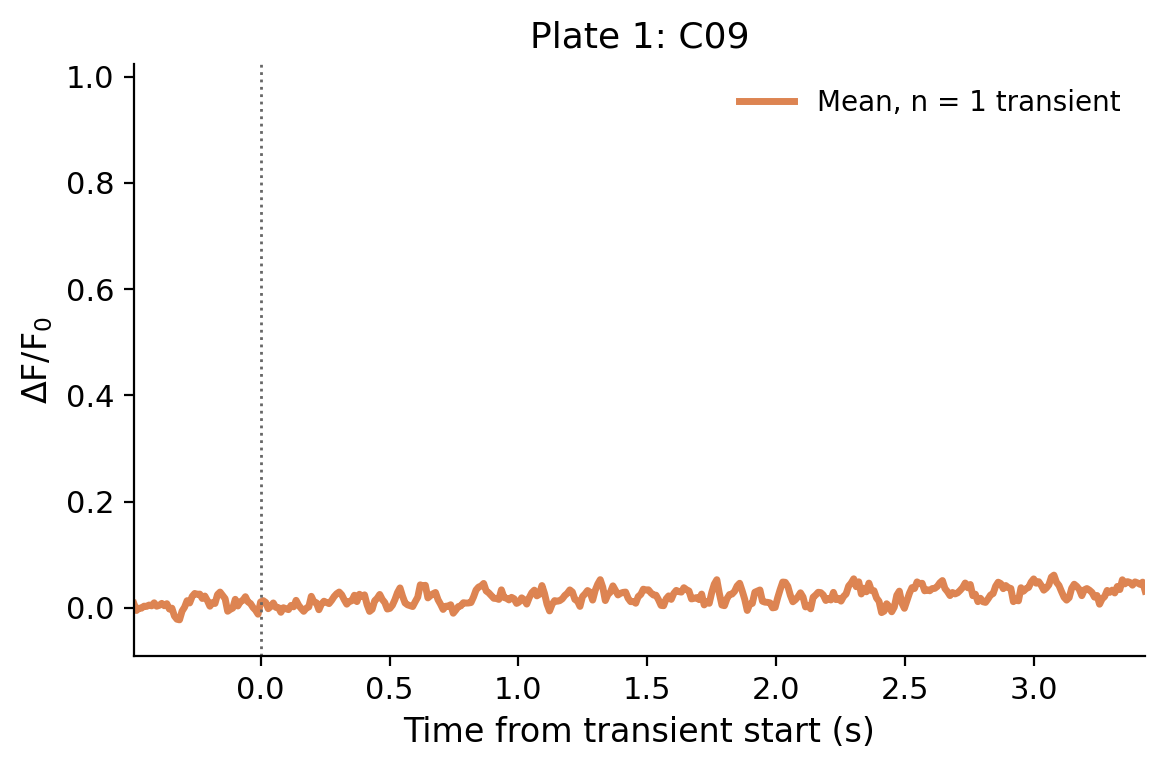

In [6]:
# Video wells on both plates; one y-axis for all four so every per-well figure is on the same scale
VIDEO_WELL_KEYS = [("plate1", "B04"), ("plate1", "C09"), ("plate2", "B06"), ("plate2", "C04")]
YLIM_WELLS = wells_ylim(aligned, VIDEO_WELL_KEYS)
print(f"shared y-range {YLIM_WELLS[0]:.2f} to {YLIM_WELLS[1]:.2f}")

# Plate 1: B04 (maintenance) and C09 (Feyen)
for plate, well in VIDEO_WELL_KEYS[:2]:
    plot_well_aligned(plate, well, aligned, ylim=YLIM_WELLS, export_name=f"{plate}_{well}_aligned-transients")

Exported: ../../Calcium/figures/presentation/plate2_B06_aligned-transients.png


Exported: ../../Calcium/figures/presentation/plate2_B06_aligned-transients.svg


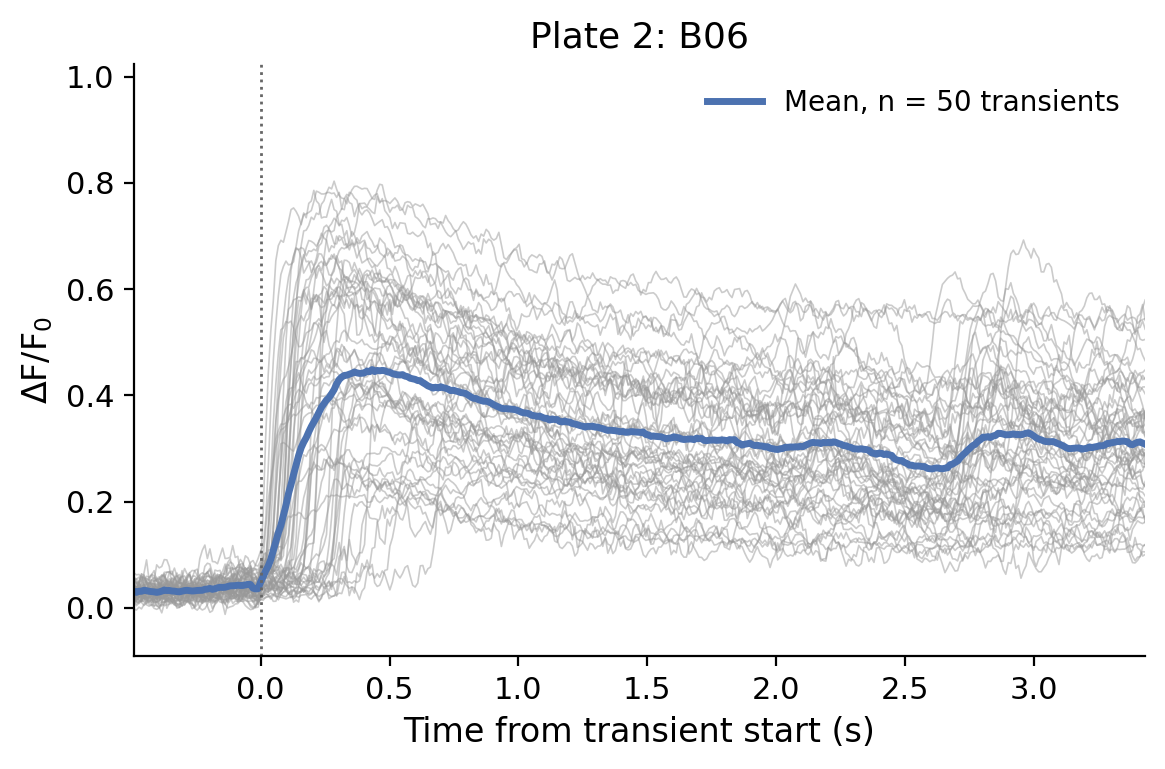

Exported: ../../Calcium/figures/presentation/plate2_C04_aligned-transients.png


Exported: ../../Calcium/figures/presentation/plate2_C04_aligned-transients.svg


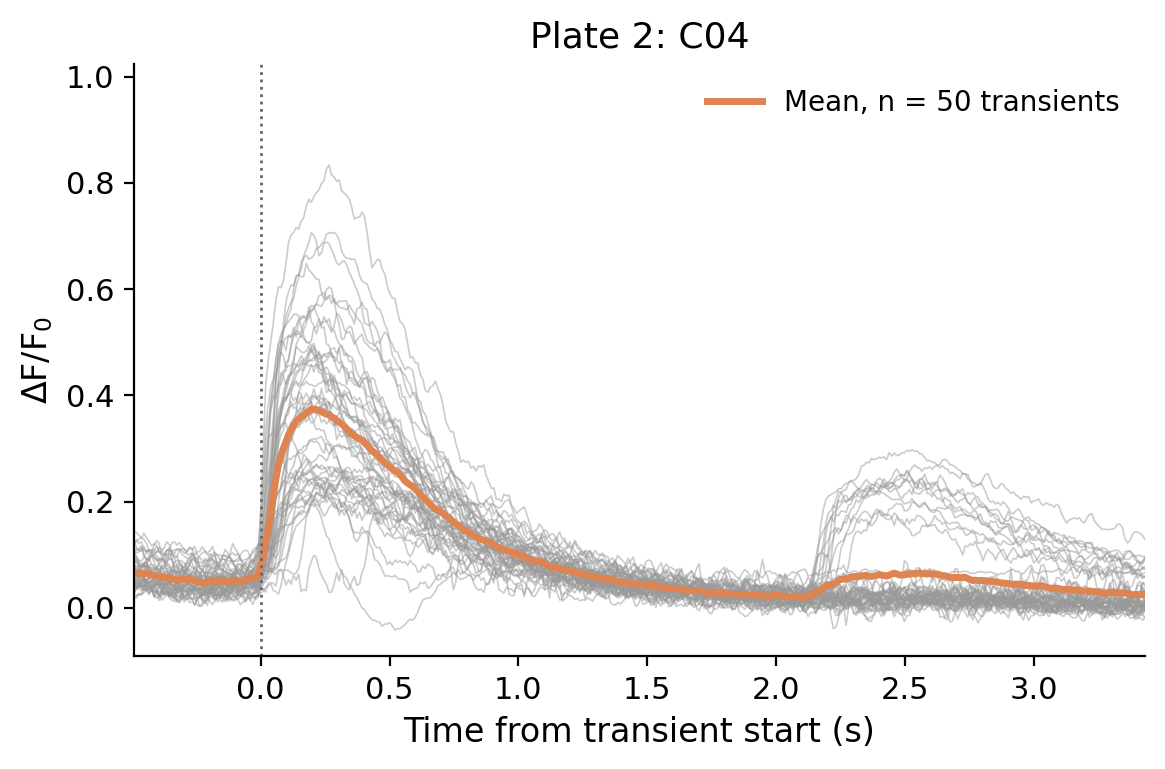

In [7]:
# Plate 2: B06 (maintenance) and C04 (Feyen)
for plate, well in VIDEO_WELL_KEYS[2:]:
    plot_well_aligned(plate, well, aligned, ylim=YLIM_WELLS, export_name=f"{plate}_{well}_aligned-transients")

#### Rhod-2 movies for slides
One well per condition per plate.

**Plate 1**
- **Maintenance: B04, hand-picked** as a clearly active well (682 active CMs, the most on Plate 1). A seeded random draw from B02-B09 first gave B08, whose beats are visible but faint (52 active CMs). On a slide, call B04 a "representative active well", not a random one.
- **Feyen:** picked at random with a fixed seed (`VIDEO_SEED = 0`) from every Feyen well except C03 (the only Feyen well on Plate 1 with transients, so it is not representative) and C07 (excluded, alignment failed).

**Plate 2:** B06 (maintenance, 935 active CMs) and C04 (Feyen, 481 active CMs), both chosen by hand. Contrast is pooled within each plate, so compare brightness within a plate, not across plates.

How the videos are made:
- **Raw Rhod-2 fluorescence**, not dF/F0, in grey. Both videos use **one contrast range per plate** (1st-99.5th percentile pooled over that plate's two movies), so brightness can be compared directly.
- **Real time:** every 3 frames are averaged (~34 fps), so the 9.8 s recording plays in 9.8 s. 102 fps is more than slide software can display, and averaging also reduces noise.
- The burned-in timestamp (top 16 rows) is cropped off and replaced by a time counter. The scale bar is 100 um (2.034 um/px). The frame is upscaled 2x so the text stays sharp.
- Saved as H.264 MP4 (plays in PowerPoint and Keynote) to `Calcium/figures/presentation/videos/`, one file per well plus a side-by-side version.

In [8]:
# Reusable functions: Rhod-2 movies for slides
import cv2
import tifffile
from matplotlib import font_manager
from PIL import Image, ImageDraw, ImageFont

import pipeline

VIDEO_DIR = FIG_DIR / "videos"
VIDEO_BIN = 3            # average every 3 frames -> ~34 fps, played in real time
VIDEO_SCALE = 2          # upscale for crisp text on slides (682 -> 1364 px wide)
TEXT_ROWS = 16           # burned-in timestamp occupies rows 0-15 of every frame: cropped off
UM_PER_PX = 2.034        # calcium movie pixel size
SCALE_BAR_UM = 100
VIDEO_SEED = 0


def movie_files(plate):
    """well -> Rhod-2 TIFF stack, found the same way as pipeline step 3. experiment.yaml has the
    cluster data_root; on the Mac the same folder is the repo's parent."""
    cfg = pipeline.load_config()
    if not cfg["data_root"].is_dir():
        cfg["data_root"] = pipeline.REPO.parent
    return pipeline.video_files(cfg, pipeline.plate_cfg(cfg, plate))


def pick_random_well(candidates, seed=VIDEO_SEED):
    """One well chosen at random from candidates, reproducibly."""
    return str(np.random.default_rng(seed).choice(sorted(candidates)))


def read_binned_movie(path, n_bin=VIDEO_BIN):
    """Rhod-2 stack with the timestamp rows cropped off, averaged over blocks of n_bin frames (float32)."""
    with tifffile.TiffFile(path) as tif:
        stack = np.stack([page.asarray()[TEXT_ROWS:] for page in tif.pages]).astype(np.float32)
    n = len(stack) // n_bin * n_bin
    return stack[:n].reshape(-1, n_bin, *stack.shape[1:]).mean(axis=1)


def display_range(movies, lo=1, hi=99.5):
    """One contrast range pooled over every movie, so brightness is comparable between videos."""
    sample = np.concatenate([m[::10].ravel() for m in movies])
    return tuple(np.percentile(sample, [lo, hi]))


def _font(size):
    return ImageFont.truetype(font_manager.findfont("DejaVu Sans"), size)


def annotate(frame8, label, t_s):
    """Upscaled frame with a label (top left), a time counter (top right) and a scale bar (bottom right)."""
    img = Image.fromarray(frame8).resize((frame8.shape[1] * VIDEO_SCALE, frame8.shape[0] * VIDEO_SCALE),
                                         Image.NEAREST).convert("RGB")
    draw = ImageDraw.Draw(img)
    font = _font(17 * VIDEO_SCALE)
    w, h = img.size
    pad = 10 * VIDEO_SCALE
    draw.text((pad, pad), label, fill="white", font=font, stroke_width=2, stroke_fill="black")
    draw.text((w - pad, pad), f"{t_s:4.1f} s", fill="white", font=font, anchor="ra",
              stroke_width=2, stroke_fill="black")
    bar = SCALE_BAR_UM / UM_PER_PX * VIDEO_SCALE
    y = h - pad - 6 * VIDEO_SCALE
    draw.rectangle([w - pad - bar, y, w - pad, y + 4 * VIDEO_SCALE], fill="white")
    draw.text((w - pad - bar / 2, y - 4 * VIDEO_SCALE), f"{SCALE_BAR_UM} \u00b5m", fill="white",
              font=_font(14 * VIDEO_SCALE), anchor="md", stroke_width=2, stroke_fill="black")
    return np.asarray(img)


def write_video(frames_rgb, fps, path):
    """H.264 MP4 (plays in PowerPoint and Keynote)."""
    path.parent.mkdir(parents=True, exist_ok=True)
    h, w = frames_rgb[0].shape[:2]
    writer = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*"avc1"), fps, (w, h), True)
    if not writer.isOpened():
        raise RuntimeError(f"OpenCV could not open an H.264 writer for {path}")
    for frame in frames_rgb:
        writer.write(cv2.cvtColor(frame, cv2.COLOR_RGB2BGR))
    writer.release()
    print(f"Exported: {path}  ({len(frames_rgb)} frames at {fps:.2f} fps = {len(frames_rgb) / fps:.1f} s)")


def export_movies(plate, wells, features, side_by_side=True):
    """Real-time Rhod-2 videos for the given wells, one shared contrast range; optionally also one
    video with the wells next to each other. Returns the per-well 8-bit movies for preview."""
    files = movie_files(plate)
    dt = {w: float(features.query("Plate == @plate and Well == @w").FrameInterval_s.iloc[0]) for w in wells}
    movies = {w: read_binned_movie(files[w]) for w in wells}
    lo, hi = display_range(movies.values())
    print(f"{plate}: display range {lo:.0f}-{hi:.0f} counts (pooled over {', '.join(wells)})")
    movies8 = {w: (np.clip((m - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8) for w, m in movies.items()}
    fps = 1 / (VIDEO_BIN * np.mean(list(dt.values())))
    labels = {w: f"{PLATES[plate].split(':')[0]} {w}: {CONDITION_LABELS[features.query('Plate == @plate and Well == @w').Condition.iloc[0]]}"
              for w in wells}
    annotated = {}
    for w in wells:
        t = (np.arange(len(movies8[w])) * VIDEO_BIN + (VIDEO_BIN - 1) / 2) * dt[w]
        annotated[w] = [annotate(f, labels[w], ts) for f, ts in zip(movies8[w], t)]
        condition = CONDITION_LABELS[features.query("Plate == @plate and Well == @w").Condition.iloc[0]].lower()
        write_video(annotated[w], fps, VIDEO_DIR / f"{plate}_{w}_{condition}.mp4")
    if side_by_side and len(wells) > 1:
        n = min(len(a) for a in annotated.values())
        gap = np.zeros((annotated[wells[0]][0].shape[0], 8 * VIDEO_SCALE, 3), np.uint8)
        frames = [np.hstack(sum([[annotated[w][i], gap] for w in wells], [])[:-1]) for i in range(n)]
        write_video(frames, fps, VIDEO_DIR / f"{plate}_{'-vs-'.join(wells)}_side-by-side.mp4")
    return movies8


def plot_movie_stills(movies8, plate, export_name=None):
    """Mean and max projection of each exported movie, same contrast, as a quick check."""
    with plt.rc_context(STYLE):
        fig, axes = plt.subplots(2, len(movies8), figsize=(4 * len(movies8), 8), squeeze=False)
        for col, (well, m) in enumerate(movies8.items()):
            for row, (name, img) in enumerate([("mean", m.mean(axis=0)), ("max", m.max(axis=0))]):
                axes[row, col].imshow(img, cmap="gray", vmin=0, vmax=255)
                axes[row, col].set_title(f"{well}: {name} projection", fontsize=11)
                axes[row, col].axis("off")
        fig.suptitle(f"{PLATES[plate]}: exported movies (shared contrast)")
        fig.tight_layout()
        _save(fig, export_name)
        plt.show()
    return fig

Selected: ['B04', 'C09']


plate1: display range 144-814 counts (pooled over B04, C09)


Exported: ../../Calcium/figures/presentation/videos/plate1_B04_maintenance.mp4  (333 frames at 33.91 fps = 9.8 s)


Exported: ../../Calcium/figures/presentation/videos/plate1_C09_feyen.mp4  (333 frames at 33.91 fps = 9.8 s)


Exported: ../../Calcium/figures/presentation/videos/plate1_B04-vs-C09_side-by-side.mp4  (333 frames at 33.91 fps = 9.8 s)


Exported: ../../Calcium/figures/presentation/plate1_movie-stills.png


Exported: ../../Calcium/figures/presentation/plate1_movie-stills.svg


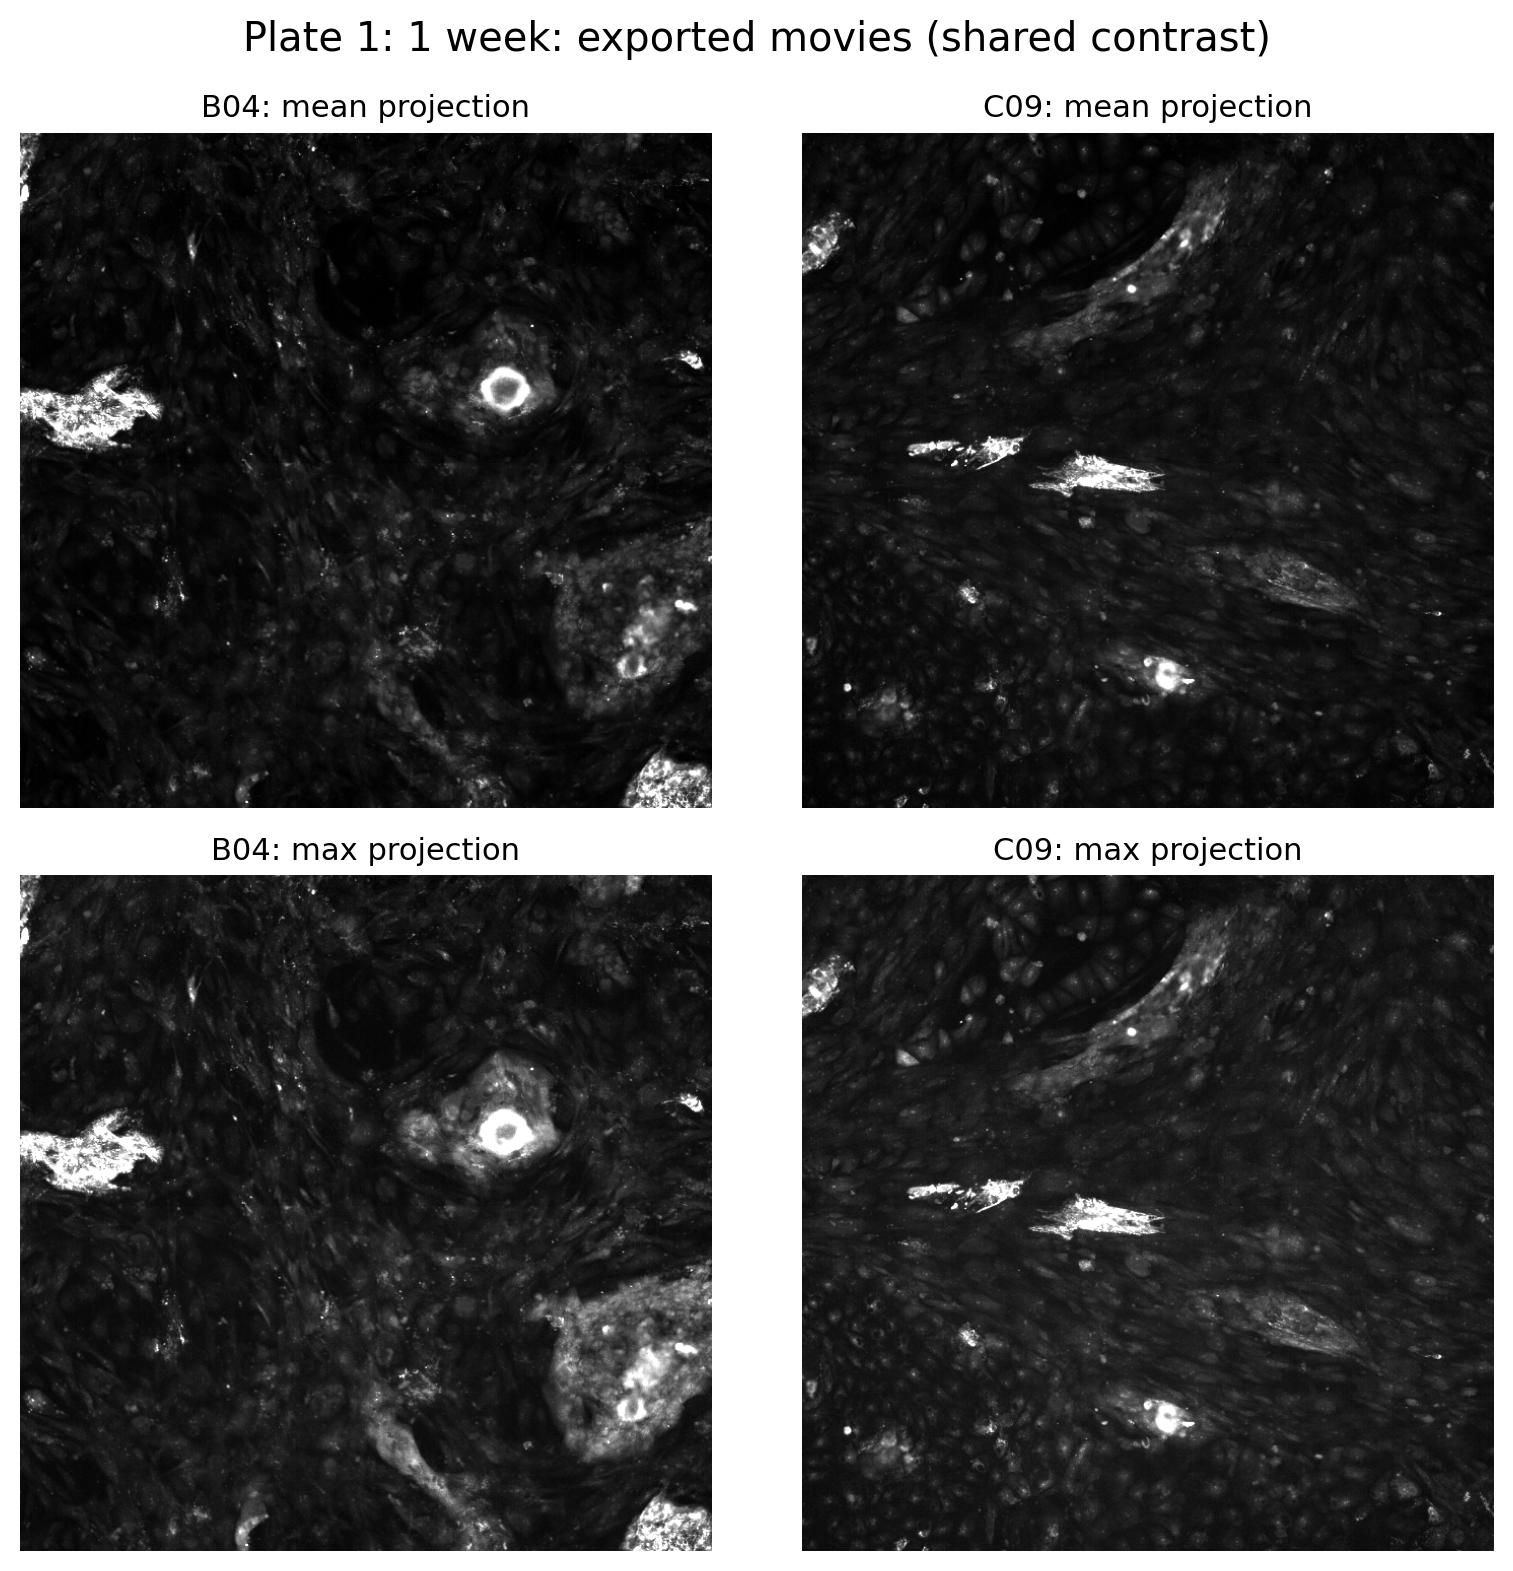

In [9]:
# Plate 1: B04 (hand-picked, clearly active maintenance well) and one random Feyen well (not C03, not excluded C07)
plate1_wells = sorted(features.query("Plate == 'plate1'").Well.unique())
video_wells = [
    "B04",
    pick_random_well([w for w in plate1_wells if w[0] == "C" and w != "C03"]),
]
print("Selected:", video_wells)
plate1_movies = export_movies("plate1", video_wells, features)
plate1_stills = plot_movie_stills(plate1_movies, "plate1", export_name="plate1_movie-stills")

plate2: display range 136-578 counts (pooled over B06, C04)


Exported: ../../Calcium/figures/presentation/videos/plate2_B06_maintenance.mp4  (333 frames at 33.91 fps = 9.8 s)


Exported: ../../Calcium/figures/presentation/videos/plate2_C04_feyen.mp4  (333 frames at 33.91 fps = 9.8 s)


Exported: ../../Calcium/figures/presentation/videos/plate2_B06-vs-C04_side-by-side.mp4  (333 frames at 33.91 fps = 9.8 s)


Exported: ../../Calcium/figures/presentation/plate2_movie-stills.png


Exported: ../../Calcium/figures/presentation/plate2_movie-stills.svg


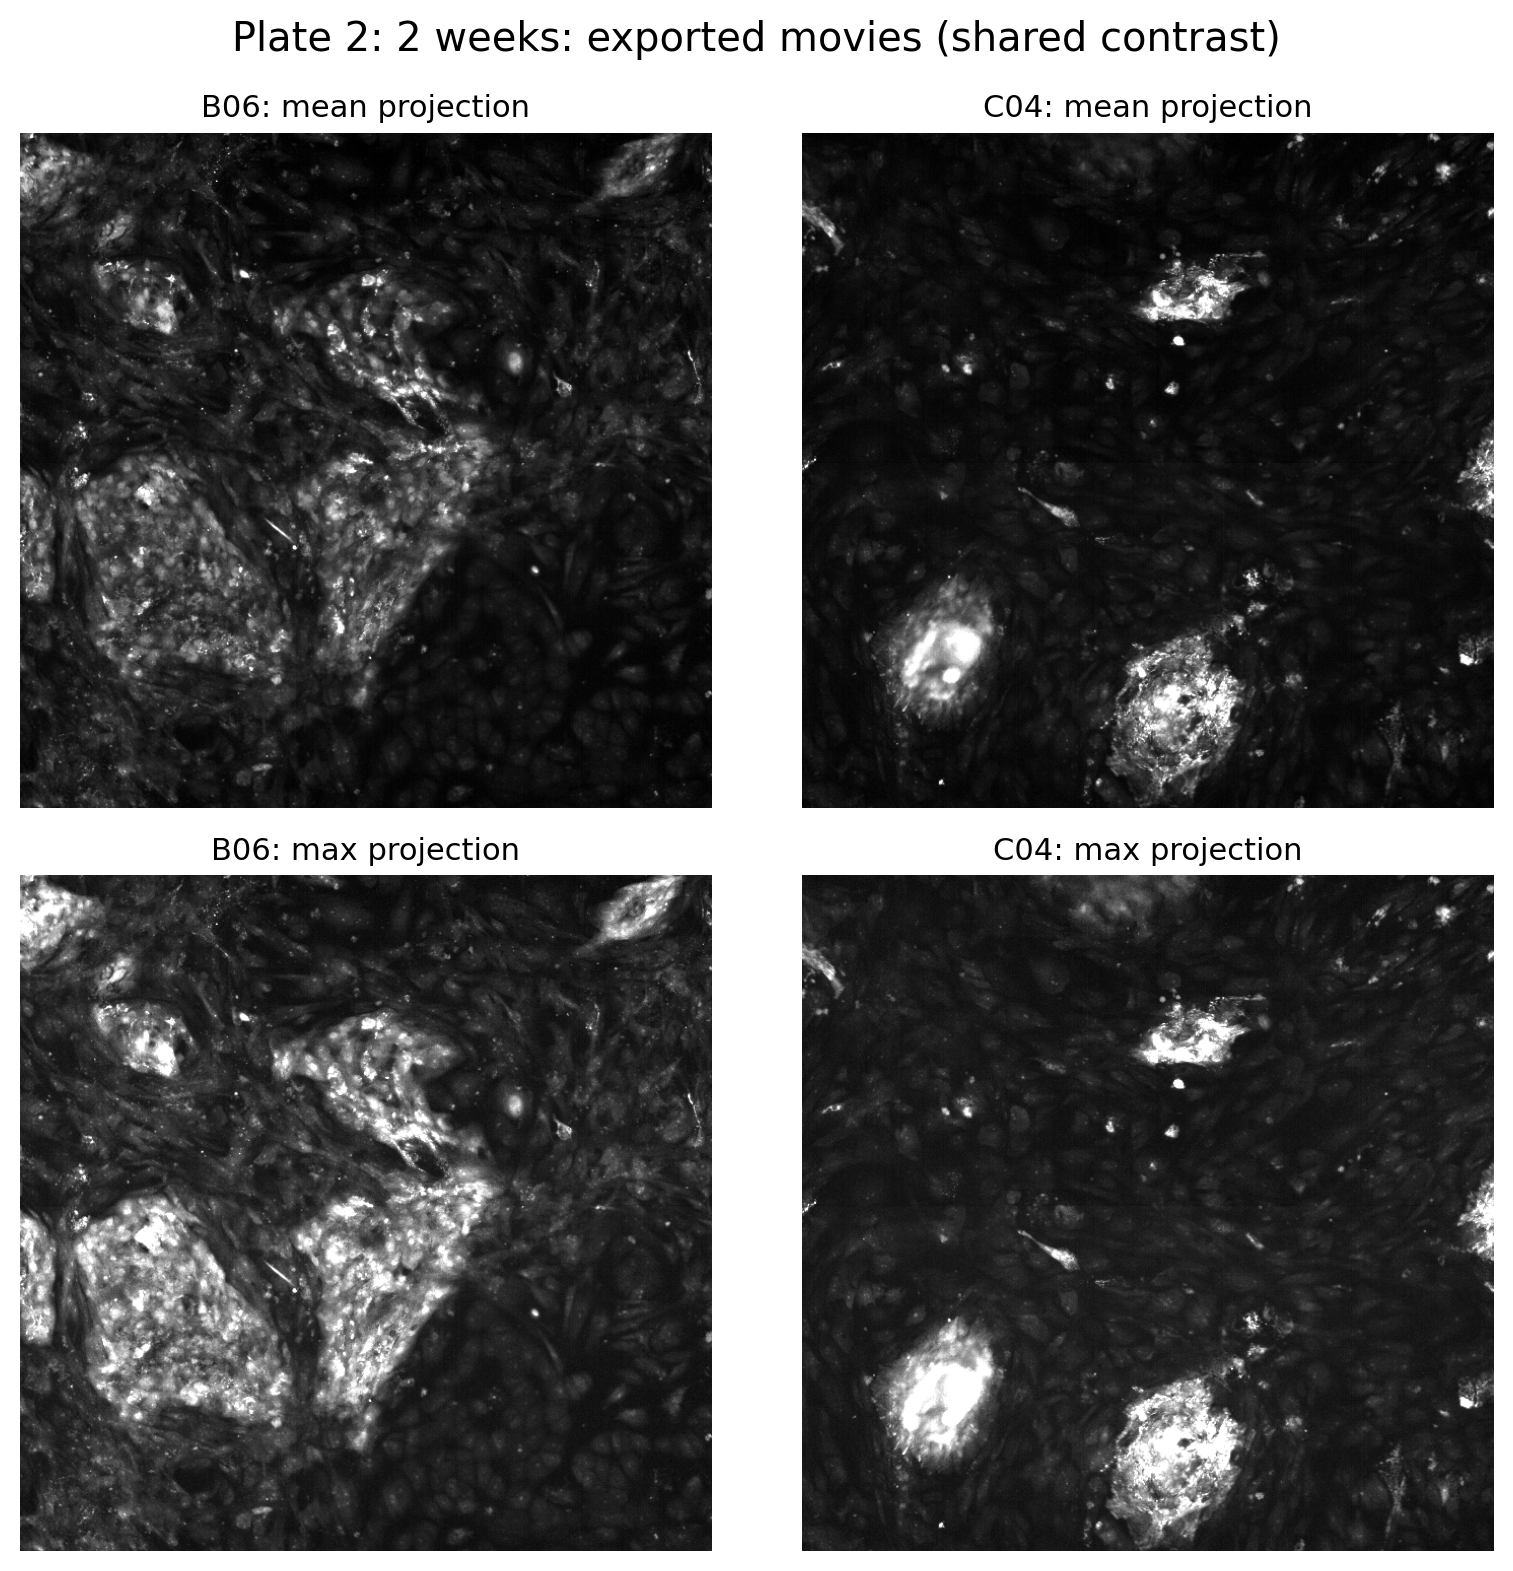

In [10]:
# Plate 2: B06 (maintenance) and C04 (Feyen), both chosen by hand
plate2_movies = export_movies("plate2", ["B06", "C04"], features)
plate2_stills = plot_movie_stills(plate2_movies, "plate2", export_name="plate2_movie-stills")